In [212]:
import numpy as np
from scipy import fft
from scipy import signal as sig
from scipy import interpolate as interp
from io import StringIO
from matplotlib import pyplot as plt
%matplotlib inline

In [52]:
def load_keysight_csv(fn):
    with open(fn, 'r') as f:
        header = {}
        while (line := f.readline().strip()) != 'DATA':
            if ',' in line:
                key, _, value = line.partition(',')
                header[key] = value
        data = f.read()
        data = np.genfromtxt(StringIO(data), delimiter=',')
        return header, data

Fundamental peak: 7996500.0 -27.0907135009766
Frequency spacing is 49.973751 kHz
3 dB frequency from spline: 0.530 GHz, equiv t_r = 0.660 ns
Reconstruction sample spacing: 0.025 ns
edge 4985:5009: t_r=0.600 ns, equiv f_3dB = 0.583 GHz


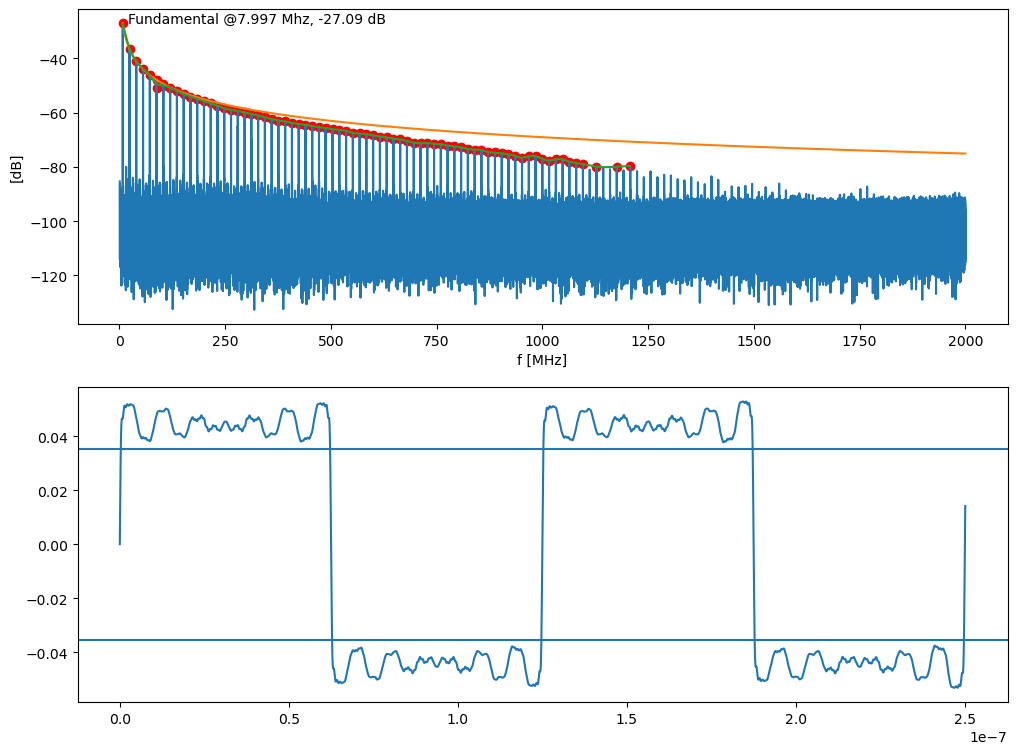

In [261]:
def plot_freq(fn):
    header_amp, data_amp = load_keysight_csv(fn)
    freq = data_amp[:,0]
    amp = data_amp[:,1]
    start_freq = float(header_amp['Start Frequency'])
    stop_freq = float(header_amp['Stop Frequency'])
    freq_spacing = (stop_freq - start_freq) / float(header_amp['Number of Points'])
    
    peaks, props = sig.find_peaks(amp, threshold=40)
    fundamental_idx = peaks[0]
    print('Fundamental peak:', freq[fundamental_idx], amp[fundamental_idx])
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))
    ax1.plot(freq/1e6, amp)
    ax1.set_xlabel('f [MHz]')
    ax1.set_ylabel('[dB]')
    ax1.annotate(f'Fundamental @{freq[fundamental_idx]/1e6:.3f} Mhz, {amp[fundamental_idx]:.2f} dB',
                (freq[fundamental_idx]/1e6, amp[fundamental_idx]),
                xytext=(5, 0),
                xycoords='data',
                textcoords='offset pixels',
               )
    
    freq_space = np.linspace(freq[fundamental_idx], stop_freq, 1000)
    sq_amp = np.sqrt(10**(amp[fundamental_idx]/10))
    sq_approx = 10*np.log10((sq_amp / (freq_space/freq[fundamental_idx]))**2)
    ax1.plot(freq_space/1e6, sq_approx)

    print(f'Frequency spacing is {freq_spacing/1e3:.6f} kHz')

    peaks, props = sig.find_peaks(amp, threshold=20, prominence=40, )
    peaks = [idx for idx in peaks if amp[idx] - 10*np.log10((sq_amp / (freq[idx]/freq[fundamental_idx]))**2) > -10]
    peak_freq = freq[peaks]
    peak_amp = amp[peaks]
    spl = interp.make_smoothing_spline(peak_freq, peak_amp, lam=1e20)
    ax1.scatter(peak_freq/1e6, peak_amp, color='red')
    freq_space_cut = freq_space[:np.argmin(freq_space < max(peak_freq))]
    ax1.plot(freq_space_cut/1e6, spl(freq_space_cut))
    kc = [(freq[idx]/freq[fundamental_idx], np.sqrt(10**(amp[idx]/10))) for idx in peaks]

    idx_3db = np.argmin(abs(spl(freq_space_cut) - sq_approx[:len(freq_space_cut)]) < 3.00)
    print(f'3 dB frequency from spline: {freq_space[idx_3db]/1e9:.3f} GHz, equiv t_r = {0.35 / freq_space[idx_3db] * 1e9:.3f} ns')
    
    t = np.linspace(0, 2, 10000)
    ts = 1/freq[fundamental_idx]
    tf = t * ts
    td_data = 4/np.pi * sum(c * np.sin(2*np.pi*k*t) for k, c in kc)
    ax2.plot(tf, td_data)
    
    lvl_high = kc[0][1]*0.8
    lvl_low = kc[0][1]*-0.8
    ax2.axhline(lvl_low)
    ax2.axhline(lvl_high)
    print(f'Reconstruction sample spacing: {(tf[1]-tf[0])*1e9:.3f} ns')

    state = None
    edge_start, edge_end = None, None
    for i, (dp, dn) in enumerate(zip(td_data, td_data[1:])):
        if dp <= lvl_low and dn >= lvl_low:
            if state != 'edge':
                state = 'edge'
                edge_start = i
        elif dp <= lvl_high and dn >= lvl_high:
            if state == 'edge':
                edge_end = i
                tr = tf[edge_end]-tf[edge_start]
                print(f'edge {edge_start}:{edge_end}: t_r={tr*1e9:.3f} ns, equiv f_3dB = {0.35/tr/1e9:.3f} GHz')
            state = 'high'
        elif dp <= lvl_low and dn <= lvl_low:
            state = 'low'
        elif dp >= lvl_high and dn >= lvl_high:
            state = 'high'

    #fft_data = np.hstack([
    #    np.zeros(round(start_freq / freq_spacing)),
    #    10**(amp/20)])
    #fft_data = np.hstack([fft_data, fft_data[1::-1]])
    
    #time_domain_amp = fft.ifft(fft_data)
    
    #ax2.plot(time_domain_amp)
    #ax2.set_xlim([1000, 4000])
    #ax2.set_ylim([-0.5e-5, 0.5e-5])

plot_freq('amp_out_span_2g_rbw_10k_40kpt_0000.csv')

Fundamental peak: 7996500.0 -38.6481513977051
Frequency spacing is 49.973751 kHz


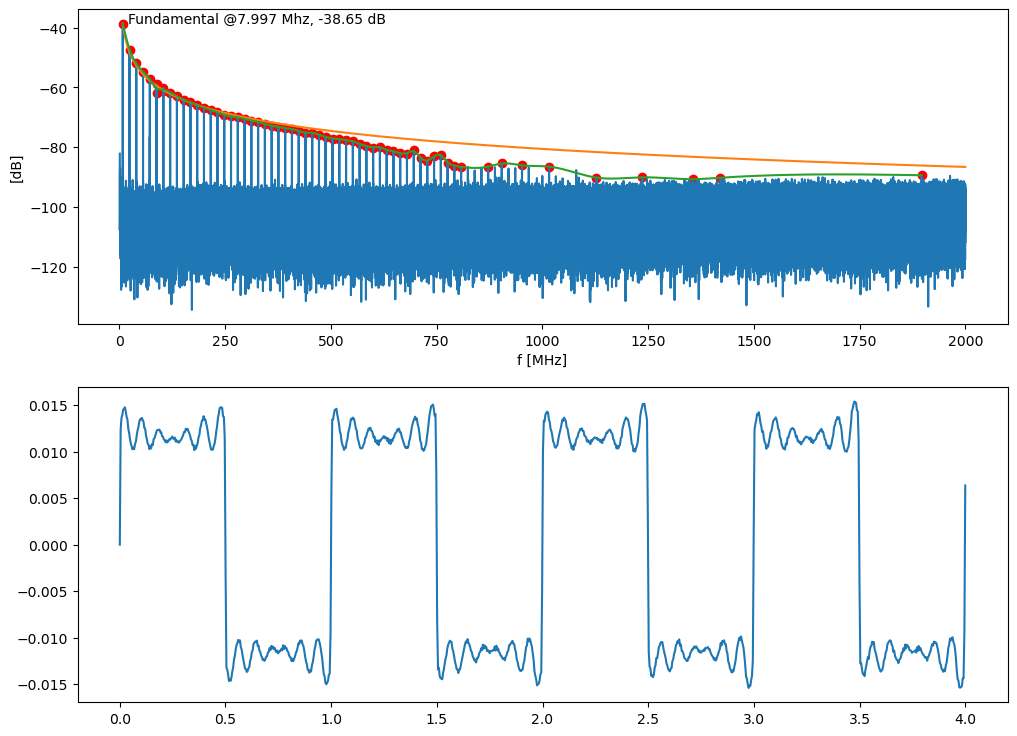

In [234]:
plot_freq('board_out_span_2g_rbw_10k_40kpt.csv')